# GDP and Life Expectancy Analysis

## Introduction
### Project Overview
This project investigates the relationship between a country's economic performance, measured by Gross Domestic Product (GDP), and the life expectancy of its population. Using historical data from multiple countries, the analysis explores trends over time and examines whether higher GDP is associated with longer life expectancy.
### Objectives
This project aims to answer the following questions:
- How has life expectancy changed over time in each country?
- How has GDP changed over time in each country?
- Is there a relationship between GDP and life expectancy?
- Which countries have the highest and lowest average life expectancy?
- How does the distribution of life expectancy compare across countries?
### Data Sources
GDP data was obtained from the World Bank. Life expectancy data was obtained from the World Health Organization (WHO).

## Import Libraries
The required libraries are imported for data manipulation and visualization.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt

## Initial Data Exploration
Before conducting the analysis, the dataset was explored to understand its structure, identify any missing values, and gain an overview of the variables it contains. This helps ensure the data is suitable for analysis and highlights any issues that may require cleaning.
## Load Dataset
The dataset was loaded successfully into a pandas DataFrame. The first five rows provide an overview of the variables available for analysis.

In [2]:
data = pd.read_csv("all_data.csv")
print(data.head())

  Country  Year  Life expectancy at birth (years)           GDP
0   Chile  2000                              77.3  7.786093e+10
1   Chile  2001                              77.3  7.097992e+10
2   Chile  2002                              77.8  6.973681e+10
3   Chile  2003                              77.9  7.564346e+10
4   Chile  2004                              78.0  9.921039e+10


### Dataset Information

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96 entries, 0 to 95
Data columns (total 4 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Country                           96 non-null     object 
 1   Year                              96 non-null     int64  
 2   Life expectancy at birth (years)  96 non-null     float64
 3   GDP                               96 non-null     float64
dtypes: float64(2), int64(1), object(1)
memory usage: 3.1+ KB


The dataset contains 96 observations and 4 columns. The variables include:

- Country – the country associated with each observation (object/string).
- Year – the year the data was recorded (integer).
- Life expectancy at birth (years) – the average life expectancy for each country and year (float).
- GDP – the gross domestic product of each country for the corresponding year (float).

All columns contain 96 non-null values, indicating that the dataset is complete. The data types are appropriate for the analysis, so no conversions are required.
### Countries Included

In [4]:
data["Country"].unique()

array(['Chile', 'China', 'Germany', 'Mexico', 'United States of America',
       'Zimbabwe'], dtype=object)

The dataset includes data for the following six countries:

- Chile
- China
- Germany
- Mexico
- United States of America
- Zimbabwe

These countries represent a range of economic sizes and levels of development, providing a suitable basis for comparing GDP and life expectancy across different nations.
### Missing Values

In [5]:
data.isnull().sum()

Country                             0
Year                                0
Life expectancy at birth (years)    0
GDP                                 0
dtype: int64

The dataset contains no missing values in any of its columns.

This means the dataset is complete and no additional data cleaning, such as removing or imputing missing values, is necessary before proceeding with the analysis.
### Summary Statistics

In [6]:
data.describe()

,Year,Life expectancy at birth (years),GDP
count,96.000000,96.000000,9.600000e+01
mean,2007.500000,72.789583,3.880499e+12
std,4.633971,10.672882,5.197561e+12
min,2000.000000,44.300000,4.415703e+09
25%,2003.750000,74.475000,1.733018e+11
50%,2007.500000,76.750000,1.280220e+12
75%,2011.250000,78.900000,4.067510e+12
max,2015.000000,81.000000,1.810000e+13


The summary statistics provide an overview of the numerical variables in the dataset.

- The data spans the years 2000 to 2015, with an average year of 2007.5, confirming that observations are evenly distributed across the study period.
- The average life expectancy is approximately 72.8 years, ranging from 44.3 years to 81.0 years, indicating substantial differences between countries.
- GDP ranges from approximately \\$4.4 billion to $18.1 trillion USD, highlighting considerable variation in the economic output of the countries included.
- The large standard deviation for GDP suggests that some countries have significantly larger economies than others, which may influence the relationship between GDP and life expectancy explored later in the analysis.
## Exploratory Data Analysis (EDA)
### Has Life Expectancy increased over time?

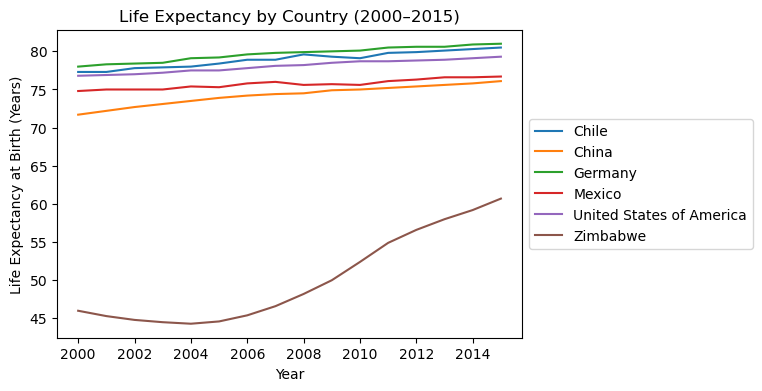

In [7]:
plt.figure(figsize=(6,4))

sns.lineplot(data=data, x="Year", y="Life expectancy at birth (years)", hue="Country")

plt.title("Life Expectancy by Country (2000–2015)")
plt.xlabel("Year")
plt.ylabel("Life Expectancy at Birth (Years)")
plt.legend(bbox_to_anchor=(1, 0.5), loc = 6)

plt.show()

The line chart shows that life expectancy increased over time in all six countries between 2000 and 2015, although the rate of improvement varied between nations.

Germany consistently had the highest life expectancy throughout the period, increasing from approximately 78 years in 2000 to over 80 years in 2015. Chile and the United States of America also maintained relatively high life expectancy levels, with both countries experiencing gradual improvements over the 15-year period.

China and Mexico showed steady increases in life expectancy. China experienced one of the largest improvements among the countries with higher life expectancy, increasing from approximately 72 years to 76 years. Mexico also showed a gradual increase, reaching around 77 years by 2015.

Zimbabwe displayed the most significant change. Unlike the other countries, Zimbabwe began with a much lower life expectancy of approximately 46 years in 2000. After a slight decline in the early 2000s, life expectancy increased substantially from around 45 years to over 60 years by 2015. Despite this improvement, Zimbabwe still had the lowest life expectancy among the countries analysed.

Overall, the results suggest that life expectancy generally improved across all six countries during the period studied. However, large differences remained between countries, indicating that factors beyond time alone, such as economic development, healthcare access, and social conditions, may influence life expectancy outcomes.

### Has GDP increased over time?

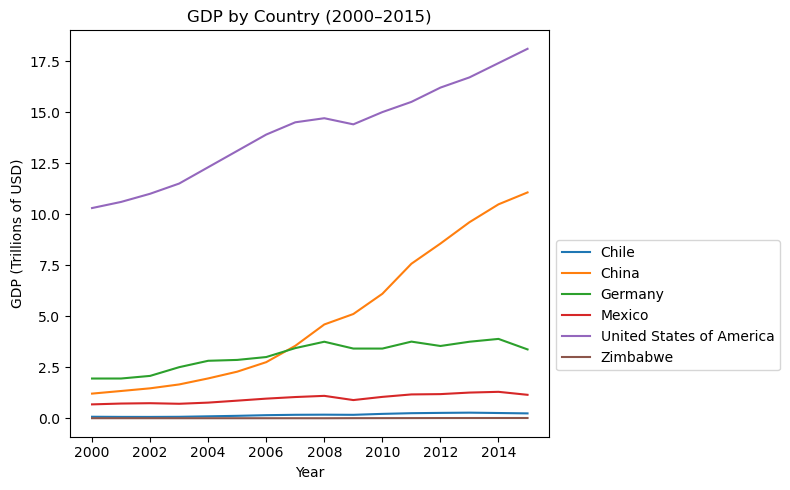

In [8]:
# Convert GDP into trillions of USD for easier interpretation
data["GDP_trillions"] = data["GDP"] / 1e12

plt.figure(figsize=(8,5))

sns.lineplot(data=data, x="Year", y="GDP_trillions", hue="Country")

plt.title("GDP by Country (2000–2015)")
plt.xlabel("Year")
plt.ylabel("GDP (Trillions of USD)")

plt.legend(bbox_to_anchor=(1, 0.5), loc="upper left")

plt.tight_layout()
plt.show()

The combined line chart shows that GDP generally increased for all six countries between 2000 and 2015, although the rate of growth varied considerably. The United States maintained the highest GDP throughout the period, while China experienced the most rapid and sustained growth, becoming the second-largest economy in the dataset by 2015. However, because all countries share the same y-axis scale, the changes in countries with much smaller economies, such as Chile, Mexico, and Zimbabwe, are difficult to distinguish. As a result, subtle trends in these countries are compressed, making it harder to compare their individual patterns of GDP growth.

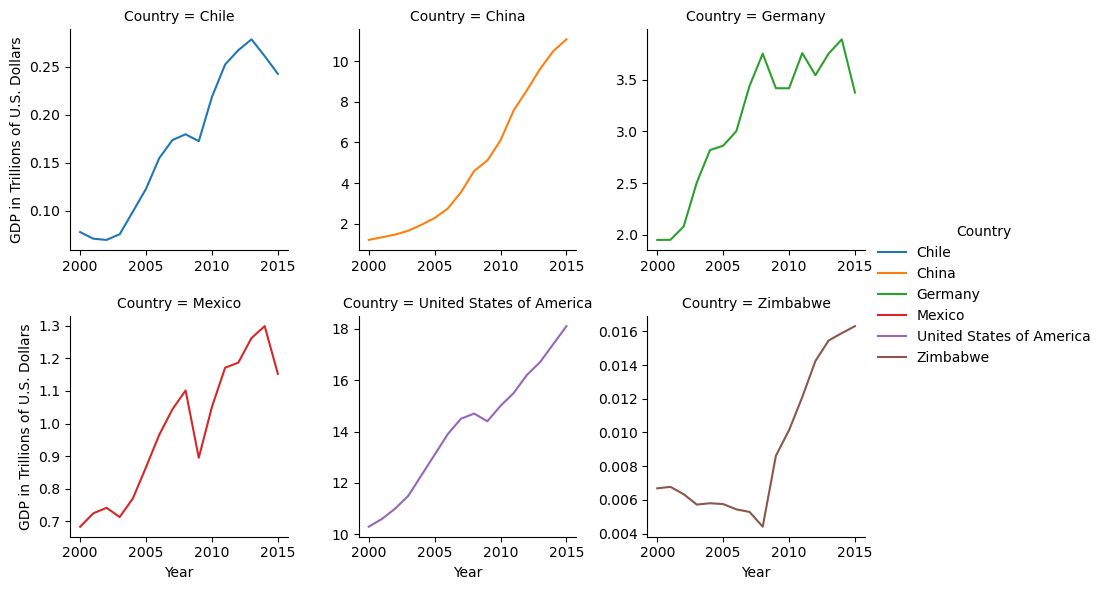

In [9]:
graphGDP = sns.FacetGrid(data=data, col="Country", col_wrap=3, hue="Country", sharey=False)

graphGDP.map_dataframe(sns.lineplot, x="Year", y="GDP_trillions")
graphGDP.set_axis_labels("Year", "GDP in Trillions of U.S. Dollars")
graphGDP.add_legend()
plt.subplots_adjust(hspace=0.3)

# Show x-axis labels on every subplot
for ax in graphGDP.axes.flat:
    ax.tick_params(labelbottom=True)

plt.show()

To better examine the GDP trends of each country, the data is displayed in separate line charts with independent y-axis scales. This makes it much easier to observe changes over time, revealing details that are less visible in the combined graph. For example, Chile shows steady growth until around 2013 before experiencing a slight decline, while Mexico and Germany exhibit periods of both growth and fluctuation. Zimbabwe also demonstrates a notable recovery after 2008, illustrating that separate scales provide a clearer view of each country's economic development regardless of its overall GDP size.
### Is there a correlation between Life Expectancy and GDP?

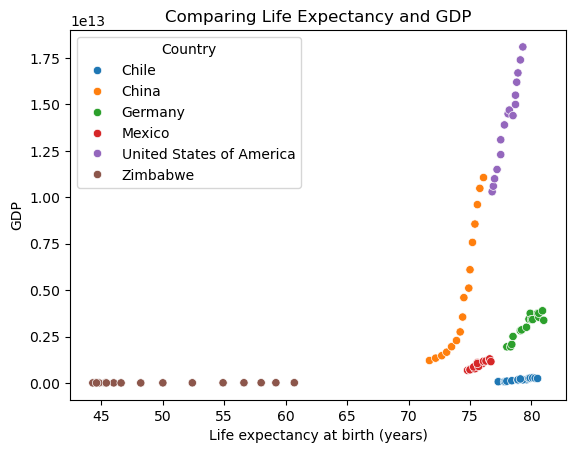

In [10]:
sns.scatterplot(data = data, x = "Life expectancy at birth (years)", y = "GDP", hue="Country")
plt.title("Comparing Life Expectancy and GDP")
plt.show()

The scatter plot suggests a positive correlation between GDP and life expectancy, with countries that have a higher GDP generally exhibiting higher life expectancy. The United States is clustered in the upper-right region of the plot, indicating both high GDP and relatively high life expectancy, while Zimbabwe is located in the lower-left region with both the lowest GDP and life expectancy. China's data points show a strong increase in GDP alongside gradual improvements in life expectancy, supporting the overall positive relationship. Although Zimbabwe appears to show very little change, this is largely because all countries share the same GDP scale, causing changes in countries with much smaller economies to be compressed and less visible.

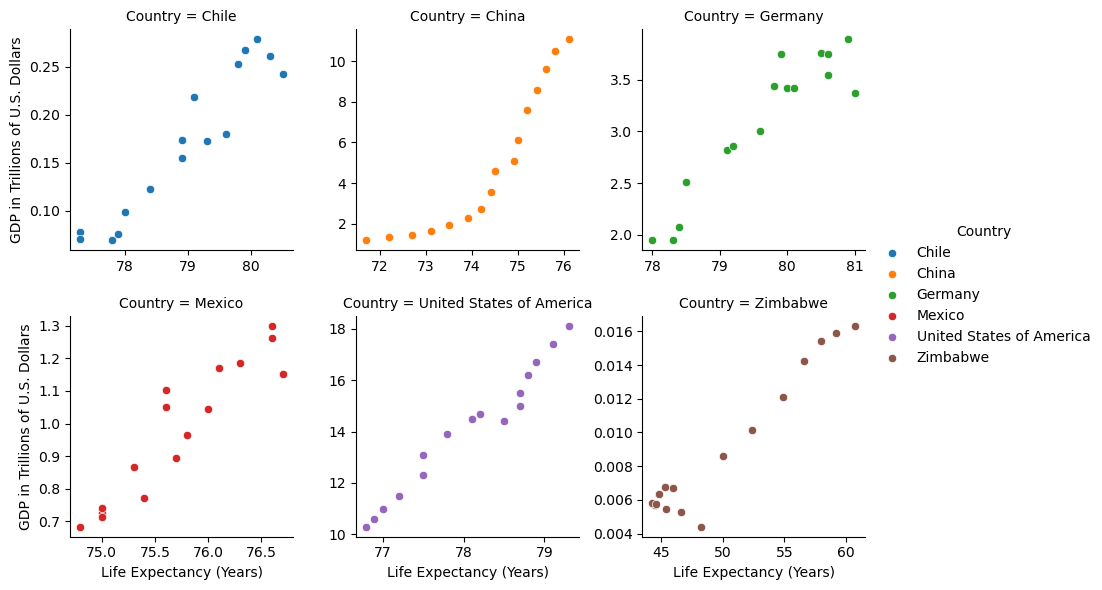

In [11]:
graphLEGDP = sns.FacetGrid(data = data, col = "Country", col_wrap = 3, hue = "Country", sharex = False, sharey = False)

graphLEGDP.map_dataframe(sns.scatterplot, x="Life expectancy at birth (years)", y="GDP_trillions")
graphLEGDP.set_axis_labels("Life Expectancy (Years)", "GDP in Trillions of U.S. Dollars")
graphLEGDP.add_legend()
plt.subplots_adjust(hspace=0.3)

# Show x-axis labels on every subplot
for ax in graphLEGDP.axes.flat:
    ax.tick_params(labelbottom=True)

plt.show()

Displaying each country on its own scatter plot with an independent x-axis and y-axis makes the relationship between life expectancy and GDP much clearer. All six countries exhibit a positive relationship, with increases in life expectancy generally accompanied by increases in GDP. China stands out from the other countries, as its GDP increases much more rapidly relative to life expectancy, producing a pattern that appears closer to exponential growth rather than the more gradual trends observed elsewhere. The individual plots also reveal that Zimbabwe experienced noticeable GDP growth as life expectancy increased, demonstrating that the apparent lack of change in the combined plot was primarily a result of the shared scale rather than an absence of economic growth.
### What is the average Life Expectancy of each country?

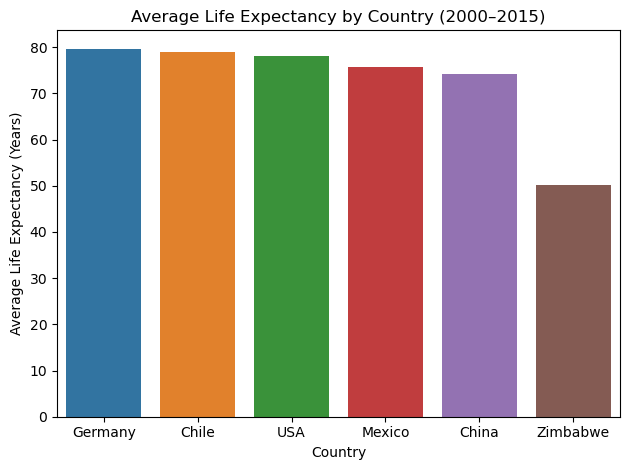

In [12]:
avg_life_expectancy = (data.groupby("Country")["Life expectancy at birth (years)"].mean().sort_values(ascending=False))
avg_life_expectancy = avg_life_expectancy.rename(index={"United States of America": "USA"})

sns.barplot(x = avg_life_expectancy.index, y = avg_life_expectancy.values, hue = avg_life_expectancy.index, legend = False)

plt.title("Average Life Expectancy by Country (2000–2015)")
plt.xlabel("Country")
plt.ylabel("Average Life Expectancy (Years)")

plt.tight_layout()
plt.show()

The bar chart compares the average life expectancy of each country between 2000 and 2015, making it easy to identify which countries have the highest and lowest averages. Germany recorded the highest average life expectancy at approximately 79.7 years, followed closely by Chile and the United States. In contrast, Zimbabwe had the lowest average life expectancy, with an average of around 52 years, considerably lower than the other countries. China and Mexico fell between these extremes, with average life expectancies of approximately 74 years and 76 years, respectively. While this chart is useful for comparing average values, it does not fully show the distribution or variability of life expectancy within each country over time.
### What is the distribution of Life Expectancy of each country?

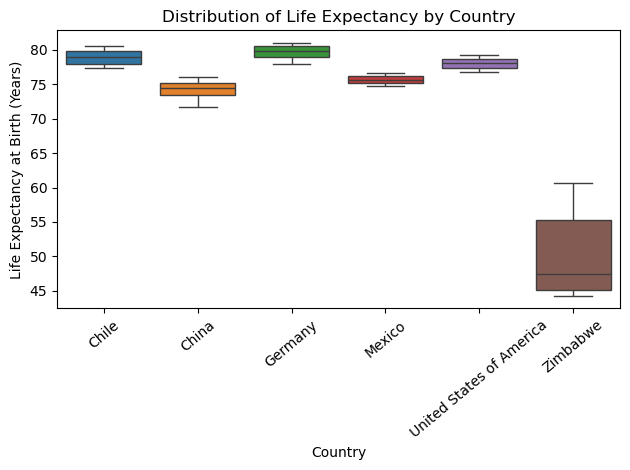

In [28]:
data = data.rename(index={"United States of America": "USA"})
sns.boxplot(data = data, x = "Country", y = "Life expectancy at birth (years)", hue = "Country")

plt.title("Distribution of Life Expectancy by Country")
plt.xlabel("Country")
plt.ylabel("Life Expectancy at Birth (Years)")

plt.xticks(rotation=40)
plt.tight_layout()
plt.show()

The box plot provides a clearer view of how life expectancy is distributed within each country by showing the median, spread, and overall range of the data. Germany has the highest median life expectancy and a relatively small spread, indicating consistently high life expectancy throughout the study period. Zimbabwe displays by far the greatest variation, with a much wider range and interquartile range than the other countries, reflecting the substantial improvements in life expectancy observed between 2000 and 2015. In comparison, Chile, Mexico, and the United States have relatively narrow boxes and whiskers, suggesting that life expectancy remained fairly stable with only gradual increases over time. No significant outliers are visible for any of the countries, indicating that the recorded values generally follow consistent trends without extreme deviations.

## Conclusion
This project investigated the relationship between GDP and life expectancy across six countries between 2000 and 2015. The analysis showed that life expectancy generally increased over time in all six countries, while GDP also experienced overall growth, particularly in China, which recorded the most rapid economic expansion. A positive relationship between GDP and life expectancy was observed, suggesting that countries with larger economies tended to have higher life expectancy, although the strength of this relationship varied between countries.

The analysis also highlighted notable differences in average life expectancy and its distribution across the six countries. Germany consistently recorded the highest life expectancy, while Zimbabwe had the lowest average but also experienced the greatest improvement over the study period. These findings suggest that economic growth may contribute to improvements in life expectancy, but it is unlikely to be the only influencing factor. Other factors, such as healthcare quality, public health policies, education, and living standards, may also play an important role and could be explored in future analyses.

## Limitations
- The dataset includes only six countries, meaning the findings cannot be generalised to all countries or regions of the world.
- The analysis covers the period 2000–2015 only and does not reflect more recent changes in GDP or life expectancy.
- This project identifies correlations rather than causation. Although countries with higher GDP often have higher life expectancy, the analysis cannot conclude that GDP directly causes increases in life expectancy.
- Life expectancy is influenced by many factors besides GDP, such as healthcare quality, education, government policies, lifestyle, and environmental conditions, which were not included in this analysis.